# Évaluation à l'échelle globale

In [1]:
import logging
import os
import sys

import numpy as np

_path = '../..'
if _path not in sys.path:
    sys.path.append(_path)

from src.mod_plot import *
from src.mod_stat import *
from src.mod_spectral import *
from src.mod_interp import *

logger = logging.getLogger()
logger.setLevel(logging.INFO)

## Paramètres

À modifier et à adapter pour chaque _mapping_ à évaluer :

In [2]:
method_name = 'FDVarNet3D18M_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget'
method_path = (
    '/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/FDVarNet3D18M_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget-n10-std0.2.nc'
)

# Méthode d'interpolation à utiliser pour le regrillage du mapping ;
# grille à utiliser pour la réinterpolation (chemin vers un fichier
# netCDF4 avec les mêmes noms de dimensions que le mapping)
interpolation_method = 'cubic'

# # Appliquer le masque des terres si le mapping à évaluer n'en contient
# # pas déjà
# apply_mask = True

Paramètres génériques, pas trop besoin de modifier (normalement) :

In [3]:
time_min = '2023-12-31'
time_max = '2025-01-01'
output_dir = './results'

# Échelles spatiales (en km) pour le filtrage du signal
lambda_min = 65.
lambda_max = 500.

# Longueur le long de la trace (en km) à considérer pour l'analyse
# spectrale
segment_length = 1000.

# lat_max = 80
# lat_min = -80

# output statistical and spectral analysis filename
stat_output_filename = f'{output_dir}/stat_sla_{method_name}.nc'
psd_output_filename = f'{output_dir}/psd_sla_{method_name}.nc'

In [4]:
#to be consistent with Daniel's setting for Miost
lat_min = None
lat_max = None

In [5]:
os.system(f'mkdir -p {output_dir}')
os.system(f'rm -f {stat_output_filename}')
os.system(f'rm -f {psd_output_filename}')

0

## Données

### Référence (Saral/AltiKa)

In [6]:
ds_alg = xr.open_dataset('alg_2024_miost_mask.nc')
ds_alg[['sla_unfiltered']]

<xarray.Dataset> Size: 238MB
Dimensions:         (time: 14867442)
Coordinates:
  * time            (time) datetime64[ns] 119MB 2024-01-01T00:14:49.803840 .....
Data variables:
    sla_unfiltered  (time) float64 119MB ...

### _Mapping_ à évaluer

In [7]:
if method_path.endswith('.nc'):
    ds_maps = (
        xr.open_dataset(method_path)
        .sel(time=slice(time_min, time_max))
        [['sla']]
    )

    resolution = (ds_maps.longitude[1] - ds_maps.longitude[0]).item()
    ds_maps = (
        ds_maps
        .pad(
            pad_width=dict(longitude=1),
            mode='wrap',
        )
        .assign(longitude=np.concatenate((
            [ds_maps.longitude[0].item() - resolution,],
            ds_maps.longitude.values,
            [ds_maps.longitude[-1].item() + resolution,],
        )))
    )

    ds_maps.longitude.attrs['units'] = 'degrees_east'
    ds_maps.latitude.attrs['units'] = 'degress_north'
else:  # DUACS, MIOST & NeurOST sont divisés en plusieurs fichiers
    ds_maps = (
        xr.open_mfdataset(
            f'{method_path}/*.nc',
            combine='nested',
            concat_dim='time',
        )
        .sel(time=slice(time_min, time_max))
        [['sla']]
    )

ds_maps

<xarray.Dataset> Size: 3GB
Dimensions:    (time: 368, latitude: 712, longitude: 1434)
Coordinates:
  * time       (time) datetime64[ns] 3kB 2023-12-31 2024-01-01 ... 2025-01-01
  * latitude   (latitude) float64 6kB -88.88 -88.62 -88.38 ... 88.38 88.62 88.88
  * longitude  (longitude) float64 11kB -0.125 0.125 0.375 ... 359.6 359.9 360.1
Data variables:
    sla        (time, latitude, longitude) float64 3GB 0.07644 ... 0.1002

Réinterpolation du _mapping_ :

In [8]:
if interpolation_method:
    ds_maps = (
        ds_maps
        .interp(
            coords=dict(
                latitude=np.arange(ds_maps.latitude[0], ds_maps.latitude[-1], 1/12),
                longitude=np.arange(ds_maps.longitude[0], ds_maps.longitude[-1] , 1/12),
            ),
            method=interpolation_method,
        )
    )
    ds_maps

In [9]:
if (lat_max is not None) or (lat_min is not None):
    ds_maps = ds_maps.sel(latitude=slice(lat_min, lat_max))

In [10]:
ds_maps.sla.isnull().any().item()

False

In [11]:
ds_maps.longitude.attrs['units'] = 'degrees_east'
ds_maps.latitude.attrs['units'] = 'degrees_north'

## Interpolation du _mapping_ le long de la trace Saral/Altika

In [12]:
ds_interp = run_interpolation(ds_maps, ds_alg)
ds_interp = ds_interp.dropna('time')
ds_interp

2026-08-12 11:14:11 INFO     fetch data from 2023-12-31 00:00:00 to 2024-02-01 00:00:00


2026-08-12 11:14:13 INFO     fetch data from 2024-01-31 00:00:00 to 2024-03-01 00:00:00


2026-08-12 11:14:15 INFO     fetch data from 2024-02-29 00:00:00 to 2024-04-01 00:00:00


2026-08-12 11:14:17 INFO     fetch data from 2024-03-31 00:00:00 to 2024-05-01 00:00:00


2026-08-12 11:14:19 INFO     fetch data from 2024-04-30 00:00:00 to 2024-06-01 00:00:00


...

2026-08-12 11:14:27 INFO     fetch data from 2024-08-31 00:00:00 to 2024-10-01 00:00:00


2026-08-12 11:14:29 INFO     fetch data from 2024-09-30 00:00:00 to 2024-11-01 00:00:00


2026-08-12 11:14:31 INFO     fetch data from 2024-10-31 00:00:00 to 2024-12-01 00:00:00


2026-08-12 11:14:33 INFO     fetch data from 2024-11-30 00:00:00 to 2025-01-01 00:00:00


<xarray.Dataset> Size: 833MB
Dimensions:            (time: 14867442)
Coordinates:
  * time               (time) datetime64[ns] 119MB 2024-01-01T00:14:49.803840...
Data variables:
    sla_unfiltered     (time) float64 119MB -0.019 0.012 0.011 ... 0.024 0.039
    lwe                (time) float64 119MB -0.011 -0.011 -0.011 ... 0.0 0.0
    latitude           (time) float64 119MB -3.058 -2.996 -2.628 ... 77.74 77.78
    longitude          (time) float64 119MB 85.06 85.04 84.96 ... 46.87 46.66
    sla_filtered       (time) float64 119MB -0.01275 -0.01134 ... -0.0146
    msla_interpolated  (time) float64 119MB -0.02016 -0.02151 ... 0.04463

Nombre de points attendus : 14 138 044

In [13]:
print(f">>> Nombre de points interpolés : {ds_interp.time.size}")

>>> Nombre de points interpolés : 14867442


## Calcul de métriques

### Métriques statistiques

In [14]:
compute_stat_scores(
    ds_interp, lambda_min, lambda_max, stat_output_filename,method_name,
)

2026-08-12 11:14:36 INFO     Compute mapping error all scales


2026-08-12 11:14:36 INFO     Compute mapping error for scales between 65.0 and 500.0 km


Total RMSE= 0.03638048167586327 m
Total RMSE score= 0.7485063487379034 m


2026-08-12 11:15:27 INFO     Compute binning statistics


2026-08-12 11:15:39 INFO     Compute statistics by oceanic regime


2026-08-12 11:15:52 INFO     Stat file saved as: ./results/stat_sla_FDVarNet3D18M_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget.nc


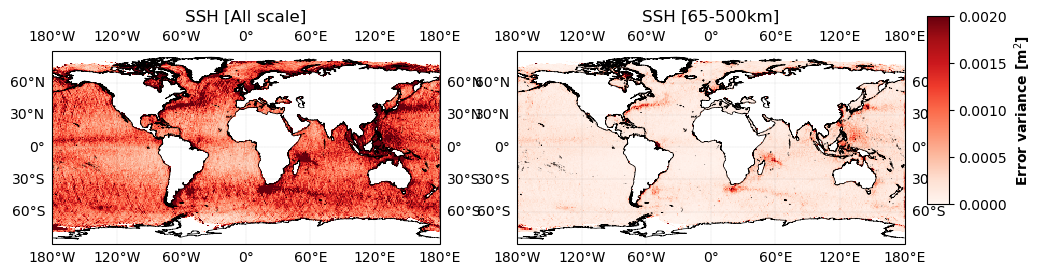

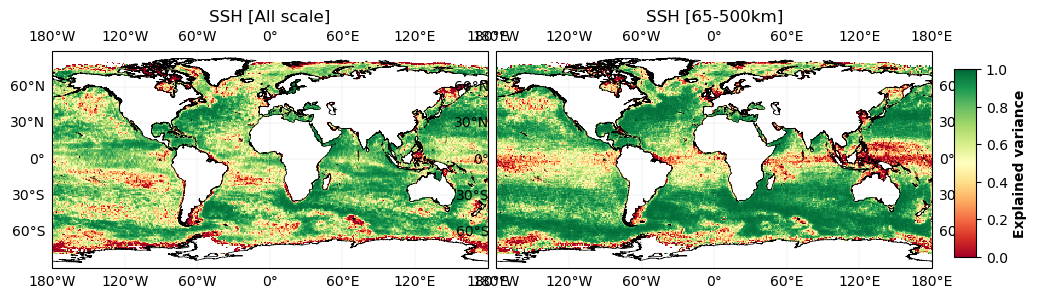

In [15]:
plot_stat_score_map_png(stat_output_filename)

In [16]:
# plot_stat_by_regimes(stat_output_filename)
plot_stat_by_regimes(stat_output_filename)[[
     'var_score_filtered', 'var_score_allscale',
    #  'rmse_score_filtered', 'rmse_score_allscale'
]]

,var_score_filtered,var_score_allscale
coastal,0.767157,0.761995
offshore_highvar,0.981604,0.967000
offshore_lowvar,0.906286,0.841591
equatorial_band,0.484894,0.778585
arctic,0.658084,0.647447
antarctic,0.411672,0.323843


### Métriques spectrales

In [17]:
compute_psd_scores_v2(
    ds_interp, psd_output_filename, lenght_scale=segment_length,
    method_name=method_name,
)

2026-08-12 11:15:58 INFO     Segment computation...


2026-08-12 11:16:03 INFO     Spectral analysis...


2026-08-12 11:19:46 INFO     Saving ouput...


2026-08-12 11:19:50 INFO     PSD file saved as: ./results/psd_sla_FDVarNet3D18M_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget.nc


Averaged effective resolution: 186.9045906145765 km


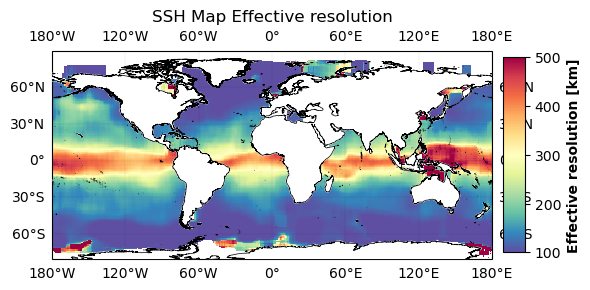

In [18]:
plot_effective_resolution_png(psd_output_filename)